# 02 · Equilibra: Copying the Owner's Moves or Learning the Owner's Rule? Money Decisions Across Different Situations

**Juan Antonio Sainz Gálvez** · Applied AI & ML, Conestoga College · [Portfolio home](../README.md)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/02_equilibra_situation_rules.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Main thesis question.** How can LLM agents learn, from an owner's approvals, rejections and corrections, a **decision profile** grounded in the owner's personality and situation (constraints and strengths: economic, skills, cognitive, family and business), so that they **minimize the gap between the agent's decision and the decision the owner would have made**, across different types of decisions, as the owner evolves, and when other users operate the system on the owner's behalf, **deferring to the owner** whenever that gap is likely to be large?
>
> **Error, in this portfolio, always means:** the agent decided differently from how the owner would have decided.

**This case:** *Equilibra* is my AI connector for studying portfolios as balances. After months of grading my own investment theses with it, I arrived at a personal rule: first pay every credit card (a guaranteed ~20% a year), then put the rest in a fixed-term deposit, and risk in stocks **only what that deposit pays in interest**, so that if the stocks went to zero I would lose only the interest, never the principal. The question for the thesis: when another user with a different situation asks the agent, does the agent decide as I would decide **in that user's situation**?


> This notebook studies how an agent imitates a decision rule. It is not financial advice, and Equilibra never recommends buying or selling; it measures.

In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})


def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="none"))
    if text:
        ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
                color=text_color, fontsize=fontsize, fontweight="bold")


def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


def thesis_card(case, profile, decision, signal):
    """The same infographic opens every notebook: owner profile -> agent decision model -> act or ask."""
    fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
    box(ax, (0.1, 0.35), 4.0, 3.5, "", PALETTE["navy"])
    ax.text(2.1, 3.45, "OWNER PROFILE", ha="center", color="white", fontsize=11, fontweight="bold")
    for i, item in enumerate(profile[:5]):
        ax.text(0.3, 2.9 - i * 0.5, "• " + item, color="white", fontsize=9, va="center")
    box(ax, (4.55, 1.55), 3.2, 1.6, "Agent learns how\nthe owner decides:\n" + decision, PALETTE["teal"], fontsize=10.5)
    box(ax, (4.55, 0.35), 3.2, 0.9, "learns from:\n" + signal, PALETTE["sky"], fontsize=9.5)
    box(ax, (8.3, 2.5), 3.5, 1.1, "Likely the same decision\nas the owner  ->  ACT", PALETTE["gold"], fontsize=10.5)
    box(ax, (8.3, 0.75), 3.5, 1.1, "Likely a different decision\n->  ASK THE OWNER", PALETTE["coral"], fontsize=10.5)
    arrow(ax, (4.1, 2.35), (4.5, 2.35)); arrow(ax, (7.8, 2.6), (8.25, 3.0)); arrow(ax, (7.8, 2.1), (8.25, 1.3))
    ax.set_title("Case: " + case, pad=4)
    plt.show()


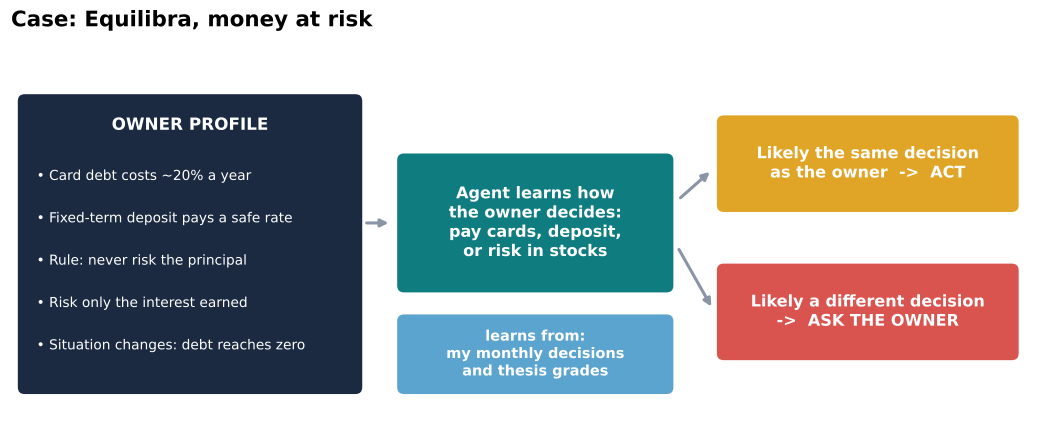

In [2]:
thesis_card("Equilibra, money at risk",
            ["Card debt costs ~20% a year", "Fixed-term deposit pays a safe rate",
             "Rule: never risk the principal", "Risk only the interest earned",
             "Situation changes: debt reaches zero"],
            "pay cards, deposit,\nor risk in stocks",
            "my monthly decisions\nand thesis grades")

## 1. Literature

| Research line | Key result | What it gives this case |
|---|---|---|
| The credit card debt puzzle [1, 2] | Around 30% of US households carry high-interest card debt while holding low-yield liquid assets; Gross and Souleles found more than a third of borrowers keep over a month of income in liquid assets while revolving debt | Paying expensive debt first is a decision many people do *not* take; an agent cannot assume it, it must learn whether *this* person does |
| Gambling with the house money [3] | After a gain, people take risks with the gain that they would not take with their own capital | My rule (risk only the interest) is a deliberate, formalized version of this effect: a personal decision style, not a market law |
| Robo-advising [4] | A robo-adviser tailored to investors' holdings had *opposite* effects for investors who were diversified and those who were not | The same advice is right for one situation and wrong for another |
| LLM agents as personalized financial advisers [5] | In a 64-person study, LLM advisers matched humans at eliciting preferences but struggled with conflicting needs; without accurate preference elicitation they could steer people to unsuitable assets, and users preferred extroverted advisers even when the advice was worse | Personalization must be measured against the person's own criterion, not user satisfaction |
| Personalized alignment [6] | One model averaged over people is wrong for each individual | Copying "the owner's average move" is the same error |

**Gap.** These studies personalize *recommendations*. The thesis asks something narrower and harder: can the agent reproduce **one person's decision rule** in another person's situation, and know when it cannot?


## 2. The owner's rule, written as a function of the situation

For a situation *s* = (cash available, card debt, card interest rate, safe deposit rate):

1. **Pay cards** = min(cash, card debt) when the card rate is above the safe rate.
2. **Deposit** = what is left.
3. **Risk budget in stocks** = deposit × safe rate (one year of interest).

All amounts below are **illustrative**, not my real balances.


In [3]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor

def owner_rule(cash, debt, card_rate, safe_rate):
    pay = min(cash, debt) if card_rate > safe_rate else 0.0
    deposit = cash - pay
    return np.array([pay, deposit, deposit * safe_rate])   # (pay cards, deposit, risk budget for stocks)

# The owner's own history: 18 months, debt falling from $24,000 at 20%, $2,500 a month to allocate
rows, debt = [], 24_000.0
for month in range(18):
    cash = 2_500.0 + (6_000.0 if month == 0 else 0.0)
    pay, dep, risk = owner_rule(cash, debt, 0.20, 0.04)
    rows.append(dict(month=month + 1, cash=cash, debt_before=debt, card_rate=0.20, safe_rate=0.04,
                     pay_cards=pay, deposit=dep, risk_budget=risk))
    debt -= pay
history = pd.DataFrame(rows)
history[["month", "debt_before", "pay_cards", "deposit", "risk_budget"]].round(0).head(12)

,month,debt_before,pay_cards,deposit,risk_budget
0,1,24000.0,8500.0,0.0,0.0
1,2,15500.0,2500.0,0.0,0.0
2,3,13000.0,2500.0,0.0,0.0
3,4,10500.0,2500.0,0.0,0.0
4,5,8000.0,2500.0,0.0,0.0
5,6,5500.0,2500.0,0.0,0.0
6,7,3000.0,2500.0,0.0,0.0
7,8,500.0,500.0,2000.0,80.0
8,9,0.0,0.0,2500.0,100.0
9,10,0.0,0.0,2500.0,100.0


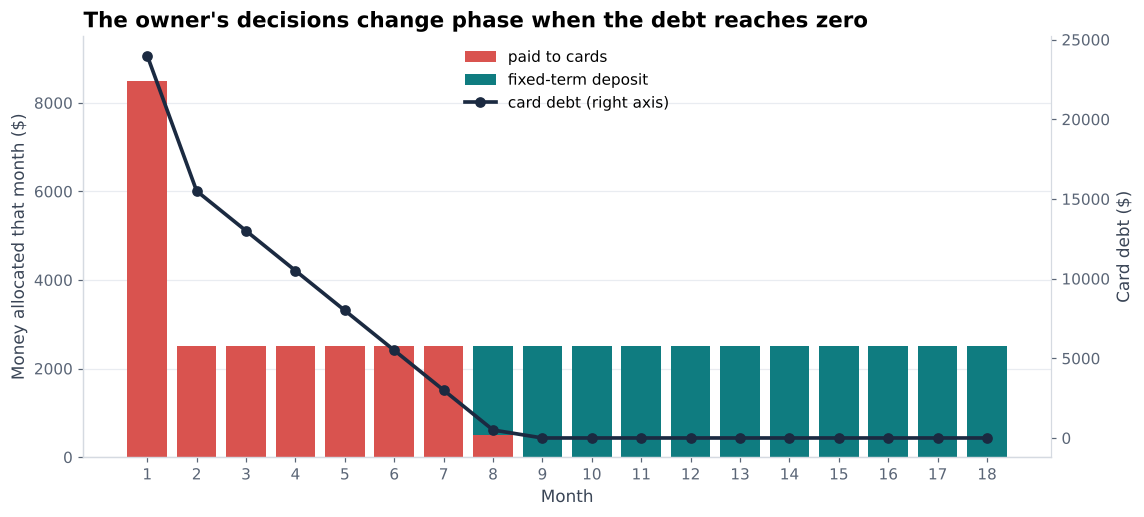

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.bar(history.month, history.pay_cards, color=PALETTE["coral"], label="paid to cards")
ax.bar(history.month, history.deposit, bottom=history.pay_cards, color=PALETTE["teal"], label="fixed-term deposit")
ax2 = ax.twinx()
ax2.plot(history.month, history.debt_before, color=PALETTE["navy"], lw=2.4, marker="o", label="card debt (right axis)")
ax2.set_ylabel("Card debt ($)"); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_xlabel("Month"); ax.set_ylabel("Money allocated that month ($)")
ax.set_xticks(history.month); ax.set_ylim(0, 9500)
ax.set_title("The owner's decisions change phase when the debt reaches zero")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 3. Experiment: 1,000 users in situations the owner never lived

Each synthetic user has cash between \$1,000 and \$50,000, card debt between \$0 and \$40,000, a card rate between 0% (promotional) and 30%, and a safe rate between 2% and 6%. Four agents decide for them:

1. **Copy the owner's last move**: allocate in the same proportions the owner used last month (by then he was debt-free).
2. **Copy the owner's average move**: the average proportions over his 18 months.
3. **Flexible model of the owner's decisions**: gradient boosting trained on the owner's 18 decisions (features: cash, debt, rates) to predict each amount.
4. **The owner's rule, learned as a function of the situation**: the agent assumes the *form* of the rule (pay debt whose rate exceeds the safe rate by some margin *m*; risk *r* times the deposit's interest) and learns *r* and *m* from the owner. The owner's history fixes *r* = 1, but only shows him paying at 20% versus 4%, so *m* could be anything between 0 and 16 points. When a user's margin falls in that unknown range, the agent **asks the owner** and narrows the range with his answer.

**Error, in money:** the dollars the agent places differently from where the owner would have placed them for that user, plus the principal put at risk beyond the owner's limit.


In [5]:
rng = np.random.default_rng(7)
N = 1000
users = pd.DataFrame(dict(cash=rng.uniform(1_000, 50_000, N), debt=rng.choice([0, 1], N, p=[0.3, 0.7]) * rng.uniform(0, 40_000, N),
                          card_rate=np.where(rng.random(N) < 0.15, 0.0, rng.uniform(0.10, 0.30, N)), safe_rate=rng.uniform(0.02, 0.06, N)))
target = np.vstack([owner_rule(*r) for r in users[["cash", "debt", "card_rate", "safe_rate"]].values])

last = history.iloc[-1]; last_frac = np.array([last.pay_cards, last.deposit, last.risk_budget]) / last.cash
avg_frac = (history[["pay_cards", "deposit", "risk_budget"]].values / history[["cash"]].values).mean(0)

X_hist = history[["cash", "debt_before", "card_rate", "safe_rate"]].values
Y_hist = history[["pay_cards", "deposit", "risk_budget"]].values
gbm = [GradientBoostingRegressor(n_estimators=200, max_depth=2, random_state=0).fit(X_hist, Y_hist[:, j]) for j in range(3)]

def agent_alloc(name, u):
    if name == "copy last move": return last_frac * u.cash
    if name == "copy average move": return avg_frac * u.cash
    if name == "flexible model":
        a = np.clip([m.predict([[u.cash, u.debt, u.card_rate, u.safe_rate]])[0] for m in gbm], 0, None)
        a[:2] = a[:2] / max(a[:2].sum(), 1e-9) * u.cash              # keep the allocation within the user's cash
        return a
    return owner_rule(u.cash, u.debt, u.card_rate, u.safe_rate)

AGENTS = ["copy last move", "copy average move", "flexible model", "owner's rule + ask when unsure"]

# What the rule agent can learn from the owner's history
dep = history[history.deposit > 0]
r_hat = float((dep.risk_budget / (dep.deposit * dep.safe_rate)).mean())          # = 1: risk exactly one year of interest
lo, hi = -1.0, float((history.card_rate - history.safe_rate).min())               # margin m is somewhere in (lo, hi]
TRUE_MARGIN = 0.0                                                                   # the owner pays whenever card rate > safe rate

res, owner_questions = [], []
for i, u in users.iterrows():
    for name in AGENTS:
        if name.startswith("owner's rule"):
            gap = u.card_rate - u.safe_rate
            if u.debt > 0 and lo < gap < hi:                       # the owner's history cannot tell: ask him
                pays = gap > TRUE_MARGIN
                if pays: hi = min(hi, gap)
                else: lo = max(lo, gap)
                owner_questions.append(i)
                res.append(dict(agent=name, misplaced=0.0, over_risk=0.0, asked=1)); continue
            pay = min(u.cash, u.debt) if (u.debt > 0 and gap >= hi) else 0.0
            a = np.array([pay, u.cash - pay, (u.cash - pay) * u.safe_rate * r_hat])
        else:
            a = agent_alloc(name, u)
        res.append(dict(agent=name, misplaced=np.abs(a[:2] - target[i, :2]).sum() / 2,
                        over_risk=max(0.0, a[2] - target[i, 2]), asked=0))
res = pd.DataFrame(res)
print(f"Questions the rule agent asked the owner: {len(owner_questions)} (users #{owner_questions}) · learned margin range: ({lo:.3f}, {hi:.3f}]")
table = res.groupby("agent").agg(median_money_placed_differently=("misplaced", "median"),
                                 mean_money_placed_differently=("misplaced", "mean"),
                                 mean_extra_principal_at_risk=("over_risk", "mean"),
                                 questions_to_the_owner=("asked", "sum")).loc[AGENTS].round(0)
table

Questions the rule agent asked the owner: 13 (users #[1, 20, 23, 52, 70, 77, 80, 153, 184, 230, 732, 874, 916]) · learned margin range: (-0.020, 0.045]


,median_money_placed_differently,mean_money_placed_differently,mean_extra_principal_at_risk,questions_to_the_owner
agent,,,,
copy last move,4279.0,8832.0,417.0,0
copy average move,7972.0,8792.0,166.0,0
flexible model,10428.0,12599.0,0.0,0
owner's rule + ask when unsure,0.0,0.0,0.0,13


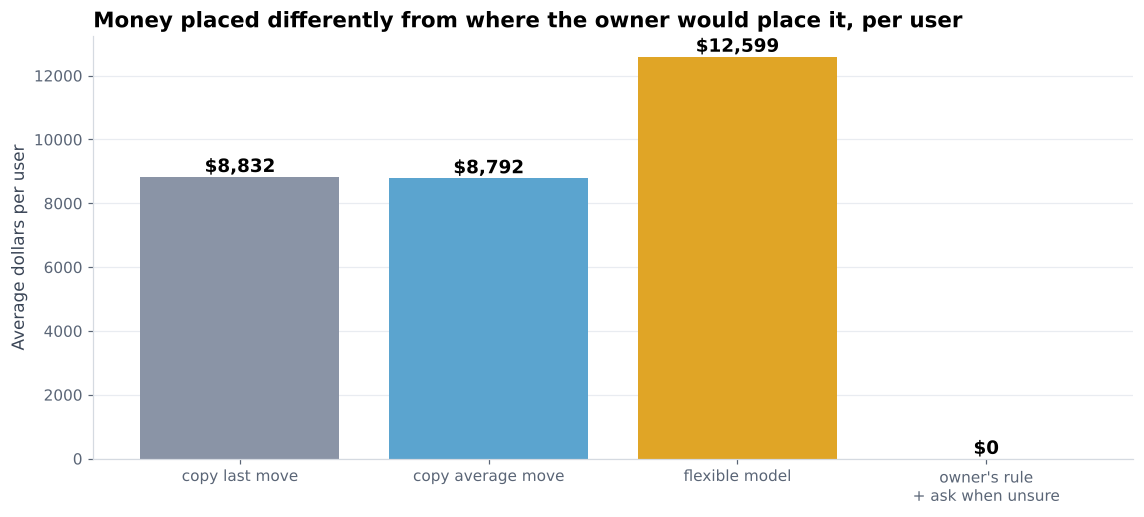

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
cols = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"]]
bars = ax.bar([a.replace(" + ", "\n+ ") for a in AGENTS], table.mean_money_placed_differently, color=cols)
for b, v in zip(bars, table.mean_money_placed_differently):
    ax.text(b.get_x() + b.get_width() / 2, v + 150, f"${v:,.0f}", ha="center", fontsize=12, fontweight="bold")
ax.grid(axis="x", visible=False)
ax.set_title("Money placed differently from where the owner would place it, per user")
ax.set_ylabel("Average dollars per user")
plt.tight_layout(); plt.show()

In [7]:
# Five users, in money terms: what the owner would do vs what each agent does
personas = pd.DataFrame([
    ("Has card debt at 22%", 10_000, 15_000, 0.22, 0.04),
    ("Debt-free, large savings", 40_000, 0, 0.00, 0.045),
    ("Small savings, big debt", 3_000, 25_000, 0.19, 0.035),
    ("Debt on a 0% promotion", 20_000, 8_000, 0.00, 0.05),
    ("Owner today (debt paid)", 2_500, 0, 0.20, 0.04)],
    columns=["user", "cash", "debt", "card_rate", "safe_rate"])
out = []
for _, u in personas.iterrows():
    t = owner_rule(u.cash, u.debt, u.card_rate, u.safe_rate)
    row = {"user": u.user, "owner would: pay cards / deposit / risk": f"${t[0]:,.0f} / ${t[1]:,.0f} / ${t[2]:,.0f}"}
    for name in AGENTS[:3]:
        a = agent_alloc(name, u)
        row[name] = f"${a[0]:,.0f} / ${a[1]:,.0f} / ${a[2]:,.0f}"
    gap = u.card_rate - u.safe_rate
    pay = min(u.cash, u.debt) if (u.debt > 0 and gap >= hi) else 0.0
    row["owner's rule agent (after its questions)"] = f"${pay:,.0f} / ${u.cash - pay:,.0f} / ${(u.cash - pay) * u.safe_rate * r_hat:,.0f}"
    out.append(row)
pd.DataFrame(out).set_index("user")

,owner would: pay cards / deposit / risk,copy last move,copy average move,flexible model,owner's rule agent (after its questions)
user,,,,,
Has card debt at 22%,"$10,000 / $0 / $0","$0 / $10,000 / $400","$4,000 / $6,000 / $240","$10,000 / $0 / $0","$10,000 / $0 / $0"
"Debt-free, large savings","$0 / $40,000 / $1,800","$0 / $40,000 / $1,600","$16,000 / $24,000 / $960","$21,421 / $18,579 / $100","$0 / $40,000 / $1,800"
"Small savings, big debt","$3,000 / $0 / $0","$0 / $3,000 / $120","$1,200 / $1,800 / $72","$3,000 / $0 / $0","$3,000 / $0 / $0"
Debt on a 0% promotion,"$0 / $20,000 / $1,000","$0 / $20,000 / $800","$8,000 / $12,000 / $480","$20,000 / $0 / $0","$0 / $20,000 / $1,000"
Owner today (debt paid),"$0 / $2,500 / $100","$0 / $2,500 / $100","$1,000 / $1,500 / $60","$0 / $2,500 / $100","$0 / $2,500 / $100"


## 4. Findings

> **Key finding 1.** Copying the owner's **moves** fails as soon as the user's situation differs from the owner's: about \$8,800 per user ends up somewhere the owner would not have put it. The agent that copies the owner's last month (debt-free) leaves indebted users paying ~20% on their cards; the agent that copies the average move pays debts that do not exist.
>
> **Key finding 2.** A flexible machine-learning model trained on the owner's decisions is **not** the owner's rule: with 18 decisions from one narrow situation, it reproduces the owner where he has been and extrapolates arbitrarily elsewhere (it is the *worst* agent here, and it sends a debt-free saver's money to cards that do not exist). More data from the same owner would not fix this, because the owner never lived those situations.
>
> **Key finding 3.** Learning the owner's decision as a **rule over the situation**, and asking only where the owner's own history cannot tell, places the money of 1,000 users the way the owner would after asking him **13 questions** (about 1 user in 77): each answer cuts the unknown range in two, like a binary search. The profile is not the owner's actions; it is the *reason* behind them, conditioned on the situation, and the agent's questions are chosen where they teach the most (active preference learning, as in [6]).

**Limitations.** One owner, a deterministic rule, and an agent that is handed the rule's *form* (it only learns the parameters). The open problem, and the thesis, is to **discover** that structure from approvals, rejections and corrections; notebook 03 measures how much faster corrections with a reason teach it than yes/no approvals.

## 5. Thesis questions this case opens

1. Can an LLM agent infer a situation-conditioned rule (not a policy over actions) from a few dozen decisions plus the owner's written theses?
2. How should the agent detect that a user's situation is outside the owner's experience, in high dimension, and ask instead of extrapolating?
3. When the owner's phase changes (debt paid), how does the agent tell a new phase of the same rule from a new rule?

## References

1. Gross, D. B., & Souleles, N. S. (2002). *Do Liquidity Constraints and Interest Rates Matter for Consumer Behavior? Evidence from Credit Card Data.* Quarterly Journal of Economics, 117(1), 149–185.
2. Vihriälä, E. (2023). *Untangling the credit card debt puzzle.* Working paper, University of Oxford (CEPR).
3. Thaler, R. H., & Johnson, E. J. (1990). *Gambling with the house money and trying to break even: The effects of prior outcomes on risky choice.* Management Science, 36(6), 643–660.
4. D'Acunto, F., Prabhala, N., & Rossi, A. G. (2019). *The Promises and Pitfalls of Robo-Advising.* Review of Financial Studies, 32(5), 1983–2020.
5. Takayanagi, T., Izumi, K., Sanz-Cruzado, J., McCreadie, R., & Ounis, I. (2025). *Are Generative AI Agents Effective Personalized Financial Advisors?* SIGIR 2025. arXiv:2504.05862.
6. Poddar, S., Wan, Y., Ivison, H., Gupta, A., & Jaques, N. (2024). *Personalizing RLHF with Variational Preference Learning.* NeurIPS 2024.
